# Example data: ArchR hematopoiesis

This notebook builds the dataset that the ArchR-parity tutorials share
(Harmony, MAGIC imputation, trajectories, marker heatmaps, browser tracks,
peak-annotation enrichment, TF regulators, module scores). It is the
hematopoiesis scATAC-seq data that ArchR uses in its own tutorial
(Granja *et al.*, *Nat Biotechnol* 2019): bone marrow, CD34+ bone marrow and
peripheral blood, aligned to hg19.

Everything runs in Python with Epione. The steps follow ArchR's tutorial
defaults where Epione has an equivalent:

| Step | Epione | ArchR equivalent |
|---|---|---|
| Download | `epi.datasets.archr_hematopoiesis` | `getTutorialData("Hematopoiesis")` |
| QC | `epi.pp.import_fragments`, `epi.pp.tsse`; keep TSS ≥ 4 and 1,000–100,000 fragments | `createArrowFiles(minTSS = 4, minFrags = 1000)` |
| Embedding | 500 bp tiles, `epi.tl.iterative_lsi` (2 iterations, 25,000 features, 30 dims) | `addIterativeLSI` |
| Clusters, UMAP | Leiden (resolution 1.2), UMAP (30 neighbours, cosine, `min_dist = 0.5`) | `addClusters`, `addUMAP` |
| Gene scores | `epi.tl.add_gene_score_matrix` | `addGeneScoreMatrix` |
| Peaks | `epi.single.macs3` per cluster with 2 pseudo-replicates, `epi.utils.merge_peaks` | `addGroupCoverages`, `addReproduciblePeakSet` |
| chromVAR | JASPAR2020 motif database, `epi.tl.add_background_peaks`, `epi.tl.compute_deviations` | `addMotifAnnotations`, `addBgdPeaks`, `addDeviationsMatrix` |

**Where the data goes.** Set `EPIONE_ARCHR_HEME` to a directory before
starting Jupyter; it defaults to `data_archr_heme/` next to the notebook. The
other tutorials read the same variable.

**Requirements.** A `macs3` executable on `PATH`, `pychromvar` for the
background peaks, and about 8 GB of disk. The
hg19 FASTA and Gencode annotation are downloaded on first use (set
`EPIONE_DATA_DIR` to reuse an existing download). With 16 cores the full run
takes about 40 minutes. Every step is cached, so re-running the notebook only
reloads the results.

In [1]:
%matplotlib inline
import os
import pathlib

os.environ.setdefault('TQDM_DISABLE', '1')  # silence per-peak progress bars

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse

import epione as epi

epi.pl.plot_set()

DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
CACHE = DATA / 'cache'
CACHE.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get('EPIONE_N_JOBS', os.cpu_count() or 1))
GENOME = epi.utils.genome.hg19
print('threads:', N_JOBS)

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.

threads: 16


## Download the fragment files

The three fragment files (about 480 MB) come from the same URLs that
`ArchR::getTutorialData("Hematopoiesis")` uses and are checked against pinned
sha256 sums. Existing files are not downloaded again.

In [2]:
frags = epi.datasets.archr_hematopoiesis(DATA)
for sample, path in frags.items():
    print(f'{sample:22s} {path.stat().st_size / 1e6:6.0f} MB')

scATAC_BMMC_R1            196 MB
scATAC_CD34_BMMC_R1       156 MB
scATAC_PBMC_R1            132 MB


## Import fragments and QC

Each sample is scanned once to count fragments per barcode. The three samples
are then merged into one tabix-indexed fragment file with ArchR-style cell
names (`<sample>#<barcode>`), which every later step reads.

In [3]:
%%time
COMBINED = DATA / 'heme_fragments.tsv.gz'
qc_file = CACHE / 'cells_raw.tsv'

if qc_file.exists() and COMBINED.exists():
    obs = pd.read_csv(qc_file, sep='\t', index_col=0)
    cells = ad.AnnData(obs=obs)
    cells.uns['files'] = {'fragments': str(COMBINED)}
    cells.uns['reference_sequences'] = pd.DataFrame(
        {'reference_seq_name': list(GENOME.chrom_sizes),
         'reference_seq_length': list(GENOME.chrom_sizes.values())})
else:
    per_sample = [
        epi.pp.import_fragments(str(p), chrom_sizes=GENOME, min_num_fragments=500)
        for p in frags.values()
    ]
    cells = epi.pp.concat_samples(
        per_sample, list(frags), [str(p) for p in frags.values()],
        combined_fragments=COMBINED, chrom_sizes=GENOME,
    )
    genes = epi.utils.get_gene_annotation(GENOME)
    epi.pp.tsse(cells, genes)
    cells.obs.to_csv(qc_file, sep='\t')

cells.obs['log10_nFrags'] = np.log10(cells.obs['n_fragment'])
cells.obs.groupby('sample').size().rename('barcodes')

└─ scanning data_archr_heme/HemeFragments/scATAC_BMMC_R1.fragments.tsv.gz


  └─ imported 5,000 cells  (16,560,340 unique fragments)
└─ scanning data_archr_heme/HemeFragments/scATAC_CD34_BMMC_R1.fragments.tsv.gz


  └─ imported 3,582 cells  (13,286,514 unique fragments)
└─ scanning data_archr_heme/HemeFragments/scATAC_PBMC_R1.fragments.tsv.gz


  └─ imported 2,708 cells  (11,649,464 unique fragments)
└─ concat_samples: writing combined fragments → data_archr_heme/heme_fragments.tsv.gz


  └─ concat_samples: indexed data_archr_heme/heme_fragments.tsv.gz
  └─ concat_samples: 11,290 cells across 3 sample(s)


└─ Computing TSS enrichment score for adata...
└─ Computing TSS enrichment score for adata...


  └─ Added TSS enrichment score to adata.obs['tss_score']
└─ Created TSS enrichment score
  └─ Added TSS enrichment score to tss_pileup.obs['tss_score']
  └─ Returned TSS enrichment score
  └─ Added TSS enrichment score to adata.obs['tsse']
CPU times: user 4min 44s, sys: 4.37 s, total: 4min 49s
Wall time: 5min 12s


sample
scATAC_BMMC_R1         5000
scATAC_CD34_BMMC_R1    3582
scATAC_PBMC_R1         2708
Name: barcodes, dtype: int64

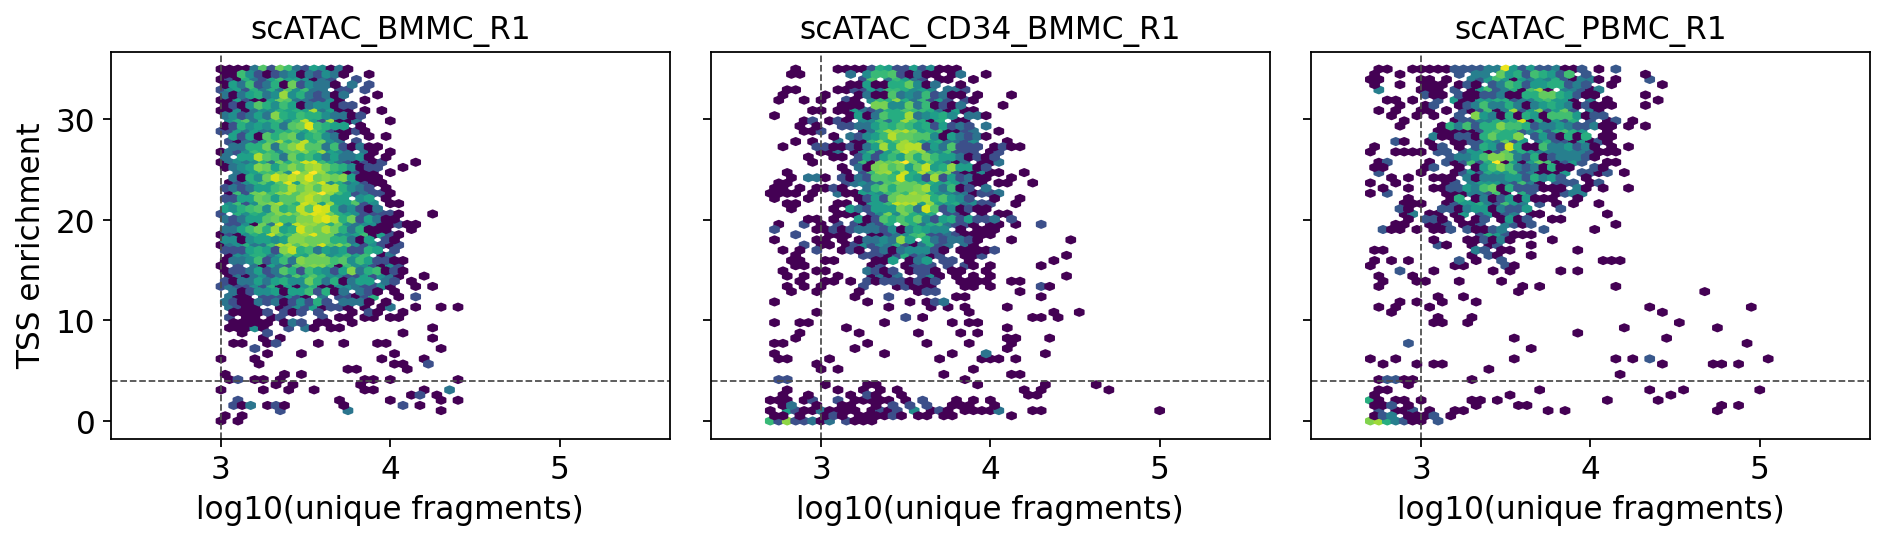

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for ax, (sample, df) in zip(axes, cells.obs.groupby('sample')):
    ax.hexbin(df['log10_nFrags'], df['tsse'], gridsize=60, bins='log',
              cmap='viridis', mincnt=1, extent=(2.5, 5.5, 0, 35))
    ax.axvline(3, color='0.3', ls='--', lw=0.8)
    ax.axhline(4, color='0.3', ls='--', lw=0.8)
    ax.set_title(sample)
    ax.set_xlabel('log10(unique fragments)')
axes[0].set_ylabel('TSS enrichment')
plt.tight_layout(); plt.show()

Keep cells with TSS enrichment ≥ 4 and 1,000–100,000 unique fragments
(ArchR's `createArrowFiles` defaults). TSS enrichment here is computed against
Gencode v41 TSSs, while ArchR uses the UCSC hg19 TxDb, so the number of
cells passing differs slightly from ArchR's.

In [5]:
keep = (
    (cells.obs['tsse'] >= 4)
    & (cells.obs['n_fragment'] >= 1000)
    & (cells.obs['n_fragment'] <= 100_000)
)
adata = cells[keep.values].copy()
adata.obs = adata.obs.rename(columns={'sample': 'Sample'})
print(f'{adata.n_obs:,} cells pass QC')
adata.obs.groupby('Sample').size().rename('cells')

10,705 cells pass QC


Sample
scATAC_BMMC_R1         4948
scATAC_CD34_BMMC_R1    3291
scATAC_PBMC_R1         2466
Name: cells, dtype: int64

## Tile matrix and iterative LSI

Counts are binned into 500 bp tiles across the genome. Iterative LSI then
runs two rounds on the 25,000 most accessible tiles: the first round clusters
a 10,000-cell sample, and the second round keeps the tiles that vary most
between those clusters.

In [6]:
%%time
tiles_file = CACHE / 'tiles_lsi.h5ad'
if tiles_file.exists():
    tiles = ad.read_h5ad(tiles_file)
    tiles.uns['files'] = {'fragments': str(COMBINED)}
else:
    tiles = adata.copy()
    epi.pp.add_tile_matrix(tiles, bin_size=500)
    tiles.X = sparse.csr_matrix(tiles.X)
    epi.tl.iterative_lsi(
        tiles, n_components=30, iterations=2, var_features=25_000,
        resolution=2.0, n_neighbors=20, sample_cells_pre=10_000,
        depth_col='n_fragment', seed=1,
    )
    tiles.write_h5ad(tiles_file)
print(f'tile matrix: {tiles.n_obs:,} cells x {tiles.n_vars:,} tiles, '
      f'LSI: {tiles.obsm["X_iterative_lsi"].shape[1]} dims')

└─ building tile matrix: 10,705 cells × 6,274,368 tiles (500 bp bins, strategy=paired-insertion)


  └─ tile matrix nnz=50,483,348


  └─ [iterative_lsi] Initial feature set: 500,000 / 6,274,368


  └─ [iterative_lsi] Iter 1/2 | fit on 10,000 cells x 500,000 features


computing neighbors


...

    finished: found 19 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


  └─ [iterative_lsi]   -> 19 clusters; selected 25,000 variable features for next round


  └─ [iterative_lsi] Iter 2/2 | fit on 10,705 cells x 25,000 features


  └─ [iterative_lsi] Done. Stored embedding (10,705 x 29) in adata.obsm['X_iterative_lsi']


tile matrix: 10,705 cells x 6,274,368 tiles, LSI: 29 dims
CPU times: user 2min 30s, sys: 7.22 s, total: 2min 37s
Wall time: 2min 25s


## Clusters and UMAP

Leiden clusters on a 30-nearest-neighbour graph of the LSI embedding, renamed
`C1`, `C2`, … by decreasing size, and a cosine UMAP with ArchR's
`minDist = 0.5`. ArchR's `addClusters(resolution = 0.4)` uses Seurat's
clustering on its own kNN graph; on this graph Leiden needs resolution 1.2 to
give the same number of clusters (11).

In [7]:
sc.pp.neighbors(tiles, use_rep='X_iterative_lsi', n_neighbors=30, metric='cosine')
sc.tl.leiden(tiles, resolution=1.2, flavor='igraph', directed=False,
             n_iterations=2, random_state=1, key_added='leiden')
order = tiles.obs['leiden'].value_counts().index
rename = {c: f'C{i + 1}' for i, c in enumerate(order)}
tiles.obs['Clusters'] = pd.Categorical(
    tiles.obs['leiden'].map(rename),
    categories=[f'C{i + 1}' for i in range(len(order))])
sc.tl.umap(tiles, min_dist=0.5, random_state=1)
tiles.obs['Clusters'].value_counts().sort_index(key=lambda s: s.str[1:].astype(int))

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)


running Leiden clustering


    finished: found 11 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)


Clusters
C1     2474
C2     1566
C3     1324
C4     1282
C5      943
C6      907
C7      511
C8      476
C9      439
C10     410
C11     373
Name: count, dtype: int64

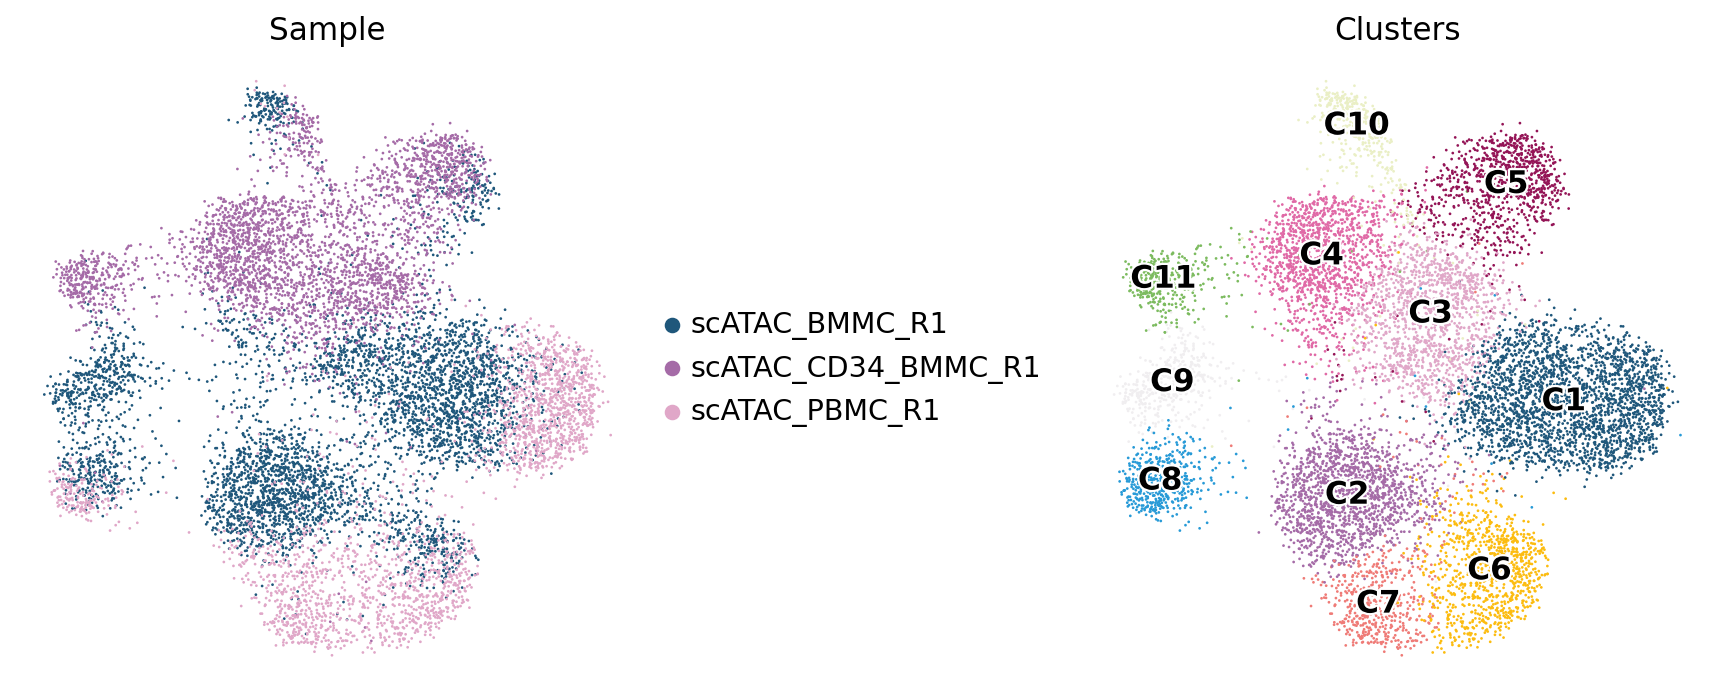

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sc.pl.umap(tiles, color='Sample', ax=axes[0], show=False, frameon=False, size=6)
sc.pl.umap(tiles, color='Clusters', ax=axes[1], show=False, frameon=False,
           size=6, legend_loc='on data', legend_fontoutline=2)
plt.tight_layout(); plt.show()

## Gene scores

ArchR's gene-score model: tile counts weighted by distance to each gene's
TSS, bounded by neighbouring genes, scaled by gene length and normalised to
10,000 per cell.

In [9]:
%%time
genes = epi.utils.get_gene_annotation(GENOME)
gs_file = DATA / 'heme_gene_scores.h5ad'
if gs_file.exists():
    gene_ad = ad.read_h5ad(gs_file)
else:
    epi.tl.add_gene_score_matrix(tiles, gene_anno=genes, tile_size=500, use_x='auto')
    gene_names = np.asarray(tiles.uns['gene_score_gene_names'])
    gene_var = (genes.drop_duplicates('gene_name').set_index('gene_name')
                .reindex(gene_names)[['chrom', 'start', 'end', 'strand']])
    gene_ad = ad.AnnData(
        X=sparse.csr_matrix(tiles.obsm['gene_score']),
        obs=tiles.obs[['Sample', 'n_fragment', 'tsse', 'Clusters']].copy(),
        var=gene_var,
    )
    gene_ad.var_names = gene_names
    gene_ad.obsm['X_iterative_lsi'] = tiles.obsm['X_iterative_lsi']
    gene_ad.obsm['X_umap'] = tiles.obsm['X_umap']
    gene_ad.write_h5ad(gs_file)
gene_ad

  └─ [gene_score] genes: 20,057 on 23 chroms (after excluding ['chrY', 'chrM'])


  └─ [gene_score] chrom-by-chrom ArchR path (fragments → uniq_tiles → W @ matGS)


  └─ [gene_score] chr=chr1  genes=2,093


  └─ [gene_score] chr=chr10  genes=742


  └─ [gene_score] chr=chr11  genes=1,319


...

  └─ [gene_score] chr=chr9  genes=797


  └─ [gene_score] chr=chrX  genes=859


  └─ [gene_score] done. obsm['gene_score'] = (10705, 20057) float32 (uns[gene_score_gene_names]: 20,057 genes)


CPU times: user 1min 15s, sys: 3.76 s, total: 1min 18s
Wall time: 1min 23s


AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters'
    var: 'chrom', 'start', 'end', 'strand'
    obsm: 'X_iterative_lsi', 'X_umap'

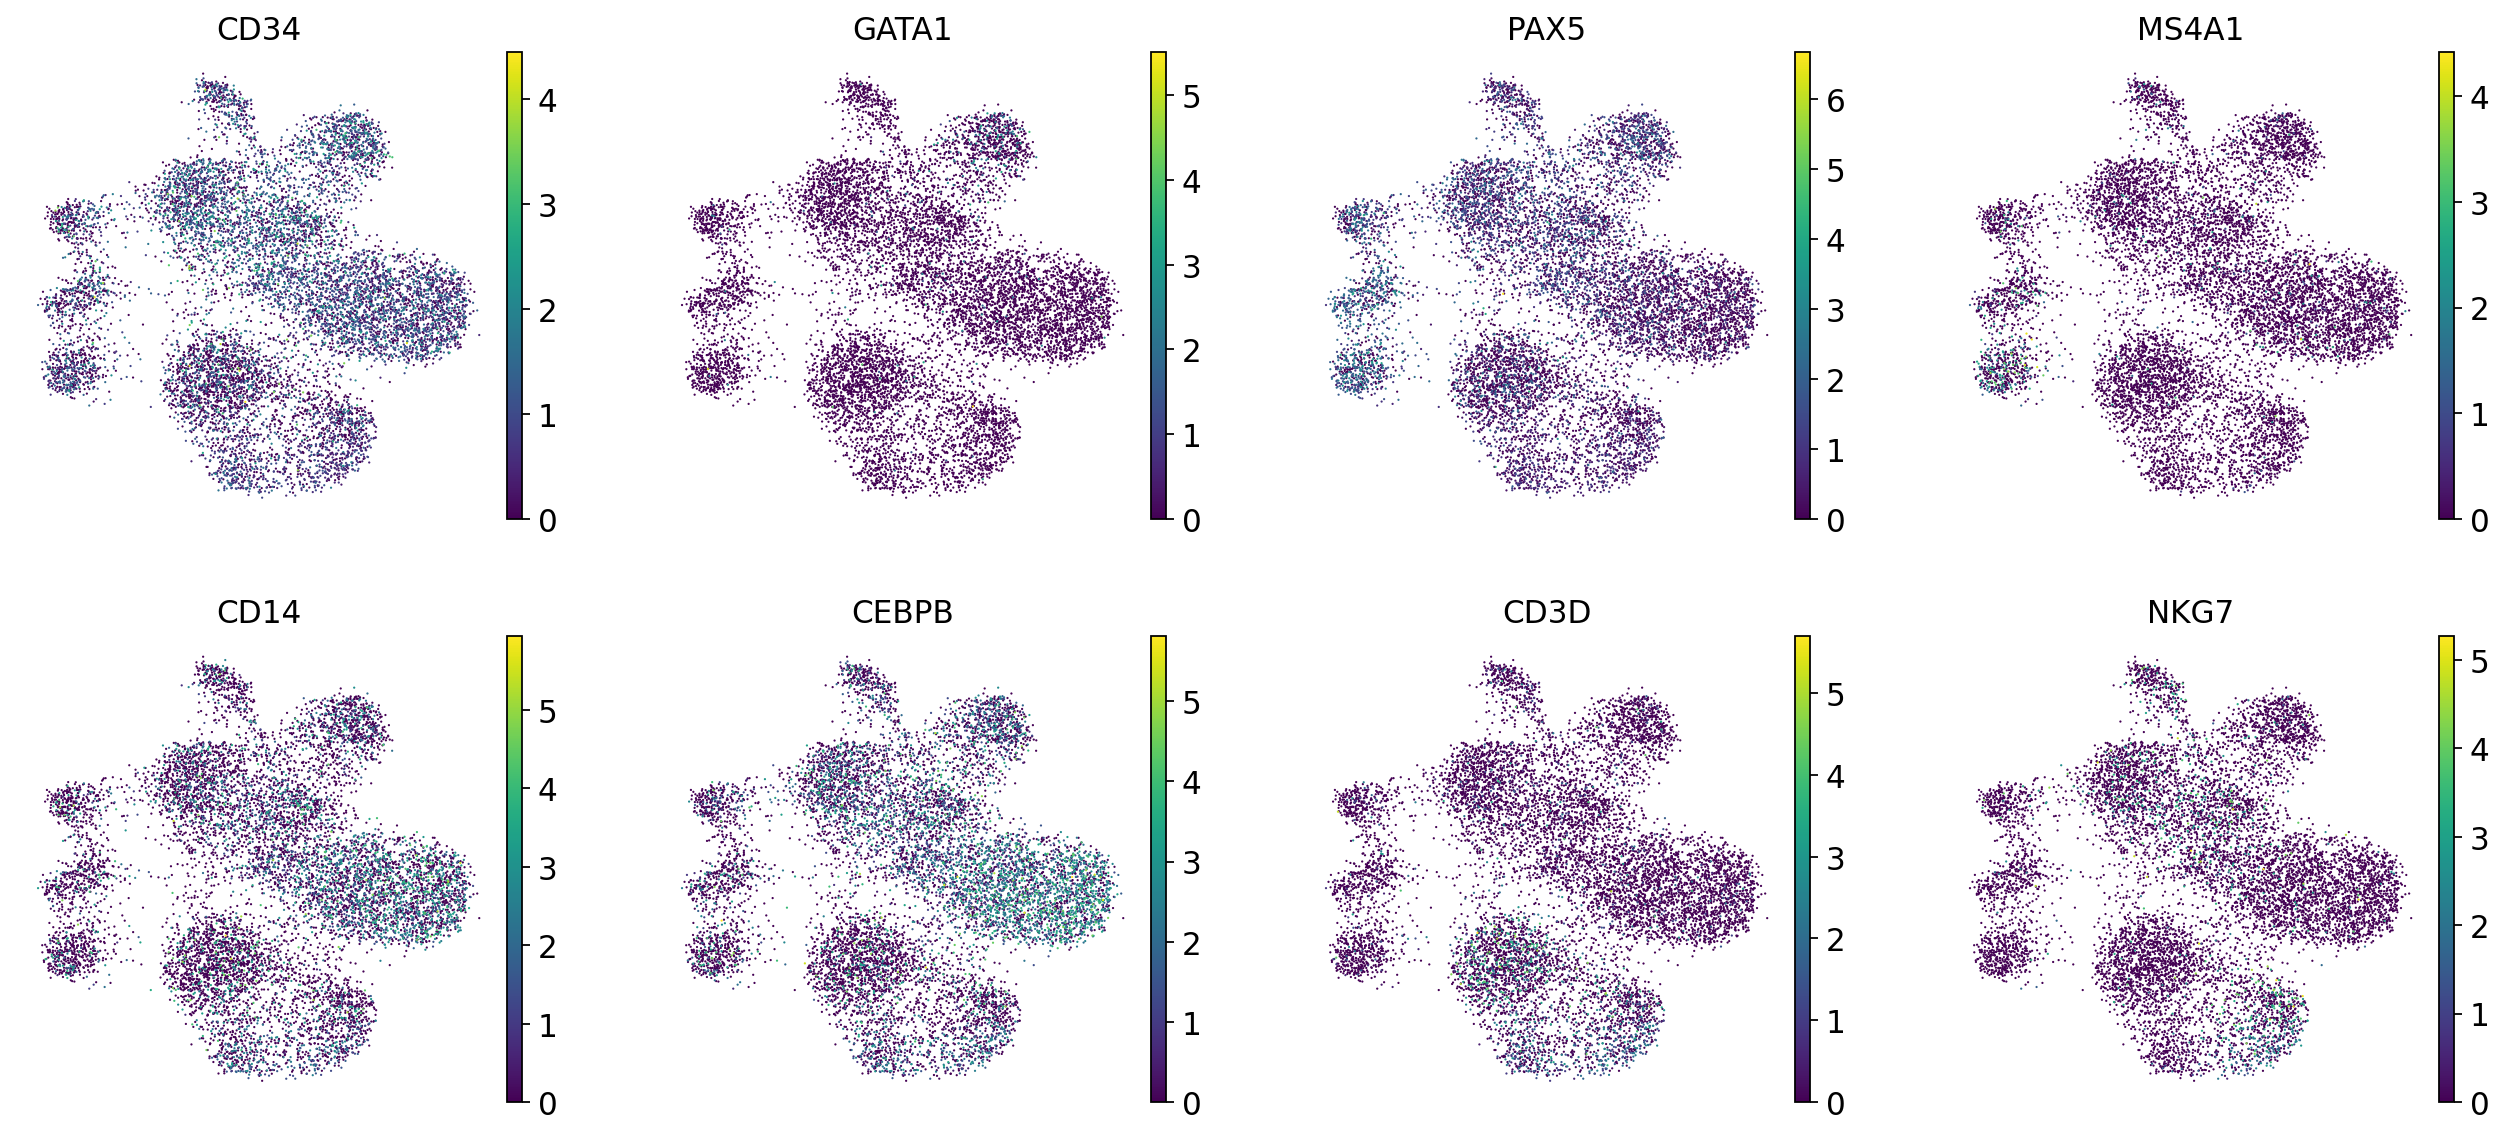

In [10]:
markers = ['CD34', 'GATA1', 'PAX5', 'MS4A1', 'CD14', 'CEBPB', 'CD3D', 'NKG7']
view = gene_ad[:, [g for g in markers if g in gene_ad.var_names]].copy()
view.X = np.log2(view.X.toarray() + 1)
sc.pl.umap(view, color=list(view.var_names), ncols=4, size=4,
           cmap='viridis', frameon=False)

## Reproducible peak set

Fragments of each cluster are split into two random pseudo-replicates and
passed to MACS3 with ArchR's settings (`--shift -75 --extsize 150 --nolambda`,
q < 0.1). A peak is kept when both replicates call it, and the per-cluster
summits are merged into fixed-width 500 bp peaks (232,272 here; ArchR also
caps the number of peaks per cluster and removes blacklisted regions, so its
peak set is smaller).

This notebook keeps MACS3 on purpose: it rebuilds ArchR's own peak set, so that the ArchR-parity tutorials built on it compare like with like. Epione's default caller is CellScan (`epi.single.call_peaks`, see the preprocessing tutorial). The MACS3 path used here is also `epi.single.call_peaks(..., method='macs3')`.

In [11]:
%%time
peaks_file = CACHE / 'peaks.tsv'
if peaks_file.exists():
    peaks = pd.read_csv(peaks_file, sep='\t')
else:
    (CACHE / 'macs3_tmp').mkdir(exist_ok=True)
    epi.single.macs3(
        tiles, groupby='Clusters', qvalue=0.1, nolambda=True,
        shift=-75, extsize=150, n_replicates=2, reproducibility=2,
        sample_ratio=0.8, extend_summits=250, seed=1,
        tempdir=CACHE / 'macs3_tmp',
    )
    peaks = epi.utils.merge_peaks(tiles.uns['macs3_pseudobulk'], GENOME, half_width=250)
    peaks = peaks[~peaks['Peaks'].str.startswith(('chrY', 'chrM'))]
    peaks.to_csv(peaks_file, sep='\t', index=False)
print(f'{len(peaks):,} peaks')

└─ MACS3 peak calling: 11 group(s) × 2 pseudo-replicates


  └─   calling peaks for 'C10_rep0' (328 cells)


  └─   calling peaks for 'C10_rep1' (328 cells)


  └─   calling peaks for 'C11_rep0' (298 cells)


  └─   calling peaks for 'C11_rep1' (298 cells)


...

  └─   group 'C7': reps=[56215, 58185]  → reproducible=47,422


  └─   group 'C8': reps=[49401, 49503]  → reproducible=41,416


  └─   group 'C9': reps=[49277, 49479]  → reproducible=40,354


  └─ merged 232,468 non-overlapping peaks


232,272 peaks
CPU times: user 4min 41s, sys: 2.64 s, total: 4min 44s
Wall time: 7min 39s


In [12]:
%%time
pm_file = CACHE / 'peak_matrix.h5ad'
if pm_file.exists():
    peak_ad = ad.read_h5ad(pm_file)
else:
    peak_ad = epi.pp.make_peak_matrix(tiles, use_rep=peaks['Peaks'].tolist())
    peak_ad.X = sparse.csr_matrix(peak_ad.X)
    peak_ad.obs = tiles.obs[['Sample', 'n_fragment', 'tsse', 'frac_dup',
                             'frac_mito', 'Clusters']].copy()
    for key in ('X_iterative_lsi', 'X_umap'):
        peak_ad.obsm[key] = tiles.obsm[key]
    coords = peak_ad.var_names.str.extract(r'^(.+):(\d+)-(\d+)$')
    peak_ad.var['chrom'] = coords[0].values
    peak_ad.var['start'] = coords[1].astype(int).values
    peak_ad.var['end'] = coords[2].astype(int).values
    peak_ad.write_h5ad(pm_file)
peak_ad.obs['FRIP'] = np.asarray(peak_ad.X.sum(axis=1)).ravel() / (2 * peak_ad.obs['n_fragment'])
print(f'peak matrix: {peak_ad.n_obs:,} cells x {peak_ad.n_vars:,} peaks, '
      f'median FRiP {peak_ad.obs["FRIP"].median():.2f}')

└─ building peak matrix: 10,705 cells × 232,272 peaks


  └─ peak matrix nnz=23,849,897


peak matrix: 10,705 cells x 232,272 peaks, median FRiP 0.56
CPU times: user 1min 6s, sys: 1.9 s, total: 1min 8s
Wall time: 1min 8s


## Motifs and chromVAR

The genome is scanned once with the JASPAR2020 CORE vertebrate motifs
(MOODS, p < 5e-5) into a per-chromosome database; annotating any peak set is
then a lookup. Background peaks are matched on GC content and accessibility
(50 per peak), and per-cell deviations use chromVAR's sampled background
(`method='sample'`, the ArchR / chromVAR algorithm).

In [13]:
%%time
MOTIF_DB = DATA / 'motif_db_hg19_jaspar2020'
epi.tl.build_motif_database(
    str(GENOME.fasta), MOTIF_DB, motif_db='JASPAR2020', p_value=5e-5,
    n_jobs=N_JOBS, verbose=False,
)
epi.tl.add_motif_matrix(peak_ad, motif_database=str(MOTIF_DB), verbose=False)
epi.tl.add_background_peaks(peak_ad, n_iterations=50, genome_fasta=str(GENOME.fasta),
                            seed=1, n_jobs=N_JOBS, verbose=False)
epi.tl.compute_deviations(peak_ad, method='sample', n_jobs=N_JOBS, verbose=False)
print('motif matrix:', peak_ad.varm['motif'].shape,
      '| deviations:', peak_ad.obsm['motif_deviations'].shape)

motif matrix: (232272, 746) | deviations: (10705, 746)
CPU times: user 7min 31s, sys: 14.4 s, total: 7min 46s
Wall time: 10min 47s


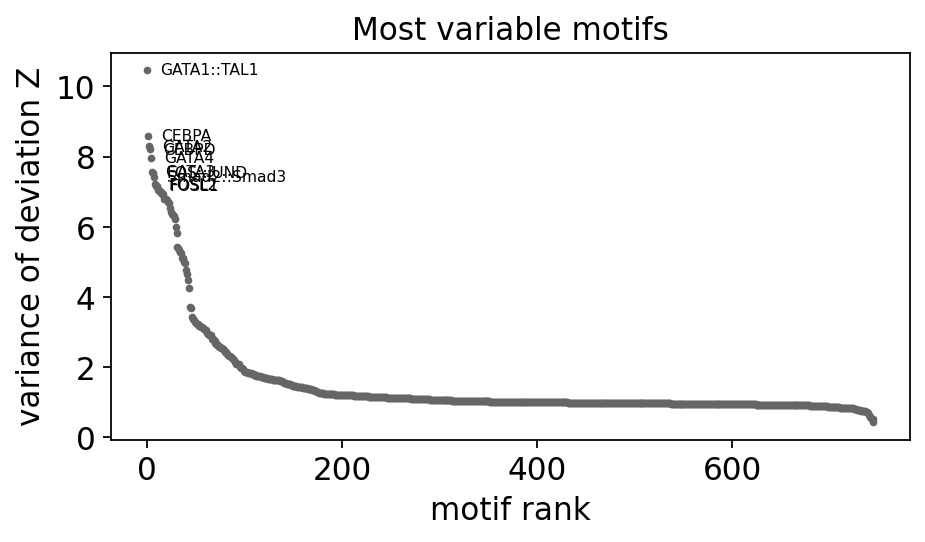

In [14]:
Z = pd.DataFrame(peak_ad.obsm['motif_deviations'], index=peak_ad.obs_names,
                 columns=np.asarray(peak_ad.uns['motif_deviations_names']))
var = Z.var().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(np.arange(len(var)), var.values, s=6, c='0.4')
for i, name in enumerate(var.index[:10]):
    ax.annotate(name.split('_', 1)[-1], (i, var.values[i]), fontsize=7,
                xytext=(6, -2), textcoords='offset points')
ax.set_xlabel('motif rank'); ax.set_ylabel('variance of deviation Z')
ax.set_title('Most variable motifs')
plt.tight_layout(); plt.show()

## Save

The tutorials load `heme_peaks.h5ad` and `heme_gene_scores.h5ad`. The
fragment path is stored relative to `EPIONE_ARCHR_HEME`.

In [15]:
peak_ad.uns['files'] = {'fragments': COMBINED.name}
peak_ad.write_h5ad(DATA / 'heme_peaks.h5ad')
gene_ad.uns['files'] = {'fragments': COMBINED.name}
gene_ad.write_h5ad(DATA / 'heme_gene_scores.h5ad')
peak_ad.obs.assign(UMAP1=peak_ad.obsm['X_umap'][:, 0],
                   UMAP2=peak_ad.obsm['X_umap'][:, 1]).to_csv(
    DATA / 'heme_cells.tsv', sep='\t')
sorted(p.name for p in DATA.iterdir())

['HemeFragments',
 'cache',
 'heme_cells.tsv',
 'heme_fragments.tsv.gz',
 'heme_fragments.tsv.gz.tbi',
 'heme_gene_scores.h5ad',
 'heme_peaks.h5ad',
 'motif_db_hg19_jaspar2020']

## Loading the dataset in other tutorials

```python
import os, pathlib, anndata as ad
DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad')         # cells x peaks, chromVAR in .obsm
genes = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')   # cells x genes
fragments = DATA / peaks.uns['files']['fragments']
```

| File | Contents |
|---|---|
| `heme_peaks.h5ad` | cells × peaks counts; `obs`: `Sample`, `Clusters`, `n_fragment`, `tsse`, `frac_dup`, `frac_mito`, `FRIP`; `obsm`: `X_iterative_lsi`, `X_umap`, `motif_deviations` (Z), `motif_deviations_raw`; `varm`: `motif`, `bg_peaks` |
| `heme_gene_scores.h5ad` | cells × genes ArchR-model gene scores; `obs`: `Sample`, `Clusters`, `n_fragment`, `tsse`; `obsm`: `X_iterative_lsi`, `X_umap` |
| `heme_cells.tsv` | cell table with UMAP coordinates |
| `heme_fragments.tsv.gz` | merged, tabix-indexed fragments with `<sample>#<barcode>` names |
| `HemeFragments/` | the three downloaded fragment files |
| `motif_db_hg19_jaspar2020/` | JASPAR2020 genome-wide motif database |
| `cache/` | intermediate results (tile matrix + LSI, peaks, peak matrix) |